In [3]:
"""
City x feature matrix of conventional health-access metrics (25 features, 17 cities).

Routing logic follows level_set_both.ipynb, with one difference: walking time
is routed to MGN *block centroids* instead of momepy tessellation cells, so that
each value links 1:1 to the DANE 2018 block table.
  - Study area: DANE urban perimeters that intersect the city's walking network.
  - Health centres: CSIMBOL codes 021001-021004, 021011, inside the study area + 1 km buffer.
  - Edge speed: slope-velocity table (5 km/h on flat edges); connectors at 5 km/h.
  - Walking time: multi-source Dijkstra; block time = network time + snap distance / 5 km/h.
  - Population weights: DANE 2018 block population; times capped at 60 min.

Usage (terminal):   python city_feature_matrix.py
Usage (notebook):   from city_feature_matrix import build_feature_matrix
                    F = build_feature_matrix()          # DataFrame, rows = cities
"""
from pathlib import Path
import time

import numpy as np
import pandas as pd
import geopandas as gpd
from scipy.sparse import coo_matrix, csr_matrix, vstack
from scipy.sparse.csgraph import dijkstra
from scipy.spatial import cKDTree

# ----------------------------------------------------------------------------- paths / parameters
cwd = Path.cwd().resolve()
REPO = next(
    path for path in (cwd, cwd / "pedestrian_accessibility", *cwd.parents)
    if (path / "data/input/shape").is_dir()
)
SHAPE = REPO / "data/input/shape"
TABLE = REPO / "data/input/table"
RESULTS = REPO / "level_sets_blocks/results/experiment_1_complete_cities"
RESULTS.mkdir(parents=True, exist_ok=True)
OUT_CSV = RESULTS / "city_feature_matrix.csv"

CITIES = ["barranquilla", "bogota", "bucaramanga", "cali", "cartagena", "cucuta", "ibague",
          "manizales", "medellin", "monteria", "neiva", "pasto", "pereira", "popayan",
          "santa_marta", "valledupar", "villavicencio"]

#HEALTH_CODES = ["021001", "021002", "021003", "021004", "021011"]
HEALTH_CODES = ["020903", "020905"]


BUFFER_M = 1000                 # external buffer for health centres (m)
CONNECTOR_SPEED = 5000 / 60     # m/min (5 km/h) for block->network and centre->network connectors
T_CAP = 60.0                    # minutes; same cap as the persistence filtration
BATCH = 40                      # health centres per Dijkstra batch (memory control)
SFCA_CATCH = 15.0               # minutes; catchment for the two-step floating catchment area (2SFCA)

FEATURES = {
    # supply
    "hosp_per100k":          "Health centres per 100k residents",
    "hosp_per_km2":          "Health centres per km² of study area",
    # walking-time distribution (population-weighted)
    "t_p25":                 "25th percentile walking time (min)",
    "t_p50":                 "Median walking time (min)",
    "t_p90":                 "90th percentile walking time (min)",
    "share_lt10":            "Share of residents < 10 min from a centre",
    "share_lt5":             "Share of residents < 5 min from a centre",
    "t_iqr":                 "Interquartile range of walking time, p75 - p25 (min)",
    "share_gt30":            "Share of residents > 30 min from a centre (coverage gap)",
    # redundancy / choice
    "share_ge3_hc15":        "Share of residents with >= 3 centres within 15 min",
    "n_hc15_pw":             "Mean number of centres reachable within 15 min (per resident)",
    "n_hc30_pw":             "Mean number of centres reachable within 30 min (per resident)",
    "share_no_hc15":         "Share of residents with no centre within 15 min",
    "share_ge2_hc15":        "Share of residents with >= 2 centres within 15 min (backup coverage)",
    "backup_penalty_p50":    "Median extra walking time if the nearest centre closed (2nd - 1st, min)",
    "t2_p50":                "Median walking time to the 2nd-nearest centre (min)",
    # catchments
    "catchment_load_pw_p50": "Median population sharing a resident's nearest centre",
    "catchment_pop_cv":      "Coefficient of variation of catchment population across centres",
    "sfca15_p50":            "2SFCA accessibility, 15-min catchment: median centres per 10k residents",
    "area_cov15":            "Share of inhabited block area within 15 min of a centre (spatial coverage)",
    # geometry / network
    "euclid_p50_m":          "Median straight-line distance to the nearest centre (m)",
    "share_beyond_800m_euclid": "Share of residents > 800 m straight-line from a centre",
    "share_net_grade_gt10":  "Share of network length with grade > 10%",
    # inequality / equity
    "gini_time":             "Gini coefficient of walking time (population-weighted)",
    "gap_bajo_alto":         "Mean walking time, low strata (1-2) minus high strata (5-6) (min)",
}


# ----------------------------------------------------------------------------- helpers
def wquantile(x, w, q):
    """Weighted quantile (linear interpolation on the cumulative weight)."""
    o = np.argsort(x)
    x, w = x[o], w[o]
    c = np.cumsum(w) / w.sum()
    return float(np.interp(q, c, x))


def wgini(x, w):
    """Population-weighted Gini coefficient."""
    o = np.argsort(x)
    x, w = x[o], w[o]
    p = np.concatenate([[0], np.cumsum(w) / w.sum()])
    L = np.concatenate([[0], np.cumsum(w * x) / (w * x).sum()])
    return float(1 - np.sum((p[1:] - p[:-1]) * (L[1:] + L[:-1])))


def edge_speeds(edges, speed_table):
    """Slope-dependent walking speed (km/h) per edge, as in the notebook."""
    sp = np.zeros(len(edges))
    g = edges["grade_abs"].to_numpy()
    for iv in speed_table.itertuples(index=False):
        sp[(g > iv.s1) & (g <= iv.s2)] = iv.speed
    sp[g == 0] = 5.0
    sp[g > speed_table["s2"].max()] = speed_table.iloc[0]["speed"]
    return sp


# ----------------------------------------------------------------------------- shared inputs (read once)
def load_shared():
    speed_table = pd.read_csv(TABLE / "slope_velocity_data.csv", sep=";")
    speed_table.columns = [c.strip("\ufeff") for c in speed_table.columns]
    perims = gpd.read_file(SHAPE / "Colombia_urban_perimeters_name_pop/Colombia_urban_perimeters_name_pop.shp")
    dane = pd.read_csv(TABLE / "DANE_2018_personas_manz.txt",
                       usecols=["MANZ_CCNCT", "poblacion", "estrato_bajo", "estrato_alto"],
                       dtype={"MANZ_CCNCT": "string"}, low_memory=False)
    return speed_table, perims, dane


# ----------------------------------------------------------------------------- per-city computation
def city_features(city, speed_table, perims_all, dane):
    t0 = time.time()

    # --- network
    edge_path = next((SHAPE / "edges").glob(f"{city}-*_edges.shp"))
    nid = edge_path.stem.removesuffix("_edges").rsplit("-", 1)[1]
    raw_nodes = gpd.read_file(SHAPE / "nodes" / f"{city}-{nid}_nodes.shp")
    crs = raw_nodes.to_crs("EPSG:4326").estimate_utm_crs()
    edges = gpd.read_file(edge_path).to_crs(crs)
    nodes = raw_nodes.to_crs(crs)
    edges["from"] = edges["from"].astype(str)
    edges["to"] = edges["to"].astype(str)
    nodes["osmid"] = nodes["osmid"].astype(str)
    edges["w"] = edges["length"] / (edge_speeds(edges, speed_table) * 1000 / 60)   # minutes

    # --- study area = urban perimeters touched by the network
    perims = perims_all.to_crs(crs)
    hits = gpd.sjoin(edges[["geometry"]], perims[["ID_mpio", "geometry"]], predicate="intersects")
    city_geom = perims[perims["ID_mpio"].isin(hits["ID_mpio"].unique())].geometry.union_all()
    area_km2 = city_geom.area / 1e6

    # --- blocks + DANE attributes
    poly = gpd.GeoDataFrame({"geometry": [city_geom]}, crs=crs)
    cand = gpd.read_file(SHAPE / "MANZANA/MGN_URB_MANZANA.shp",
                         mask=poly.to_crs("EPSG:4326").geometry.iloc[0]).to_crs(crs)
    blocks = (gpd.sjoin(cand, poly, predicate="intersects").drop(columns="index_right")
              .drop_duplicates("MANZ_CCNCT").reset_index(drop=True))
    blocks["MANZ_CCNCT"] = blocks["MANZ_CCNCT"].astype("string")
    blocks = blocks.merge(dane, on="MANZ_CCNCT", how="left", validate="one_to_one")

    # --- health centres in study area + buffer
    buf = city_geom.buffer(BUFFER_M)
    eq = gpd.read_file(SHAPE / "colombia_equipments_ID/colombia_equipments_ID.shp",
                       mask=gpd.GeoSeries([buf], crs=crs).to_crs("EPSG:4326").iloc[0]).to_crs(crs)
    eq["CSIMBOL"] = eq["CSIMBOL"].astype("string").str.strip()
    hc = eq[eq["CSIMBOL"].isin(HEALTH_CODES) & eq.geometry.intersects(buf)].reset_index(drop=True)
    H = len(hc)
    hxy = np.column_stack([hc.geometry.x, hc.geometry.y])

    # --- graph: undirected, parallel edges -> minimum time, no self-loops
    ids = pd.Index(pd.unique(np.concatenate([edges["from"].to_numpy(), edges["to"].to_numpy()])))
    u, v = ids.get_indexer(edges["from"]), ids.get_indexer(edges["to"])
    e = pd.DataFrame({"a": np.minimum(u, v), "b": np.maximum(u, v), "w": edges["w"].to_numpy()})
    e = e[e.a != e.b].groupby(["a", "b"], as_index=False)["w"].min()
    N = len(ids)

    nn = nodes.drop_duplicates("osmid").set_index("osmid").reindex(ids)
    have = nn.geometry.notna().to_numpy()
    nxy = np.column_stack([nn.geometry.x.to_numpy(), nn.geometry.y.to_numpy()])
    tree_idx = np.flatnonzero(have)
    tree = cKDTree(nxy[have])

    # one virtual source node per centre (keeps the connector cost and the centre identity)
    hd, hp = tree.query(hxy)
    hnode = tree_idx[hp]
    hcon = np.maximum(hd / CONNECTOR_SPEED, 1e-9)          # csgraph treats 0 as "no edge"
    rows = np.concatenate([e.a, e.b, N + np.arange(H)])
    cols = np.concatenate([e.b, e.a, hnode])
    vals = np.concatenate([e.w, e.w, hcon])
    G = coo_matrix((vals, (rows, cols)), shape=(N + H, N + H)).tocsr()

    # nearest centre: time + which centre
    dist, _, src = dijkstra(G, directed=True, indices=N + np.arange(H),
                            min_only=True, return_predecessors=True)
    # --- attach blocks to the network (centroid -> nearest network node)
    cen = blocks.geometry.centroid
    bxy = np.column_stack([cen.x, cen.y])
    bd, bp = tree.query(bxy)
    bn = tree_idx[bp]
    snap_t = bd / CONNECTOR_SPEED
    pop_all = blocks["poblacion"].fillna(0).to_numpy(float)

    # counts within 15/30 min, 2nd-nearest time and the centre->block 15-min reach matrix
    # (batched, truncated at T_CAP)
    reach_rows = []
    n15 = np.zeros(N, np.int32)
    n30 = np.zeros(N, np.int32)
    best = np.full(N, np.inf)
    second = np.full(N, np.inf)
    for i0 in range(0, H, BATCH):
        D = dijkstra(G, directed=True, indices=N + np.arange(i0, min(H, i0 + BATCH)), limit=T_CAP)[:, :N]
        n15 += (D <= 15).sum(0)
        n30 += (D <= 30).sum(0)
        stack = np.vstack([best, second, D])
        stack.sort(axis=0)
        best, second = stack[0], stack[1]
        reach_rows.append(csr_matrix((D[:, bn] + snap_t[None, :]) <= SFCA_CATCH))   # centres x blocks

    # --- 2SFCA (Luo & Wang 2003), binary 15-min catchment, every centre has capacity 1
    reach = vstack(reach_rows).tocsr().astype(float)       # H x n_blocks
    demand = reach @ pop_all                                # residents within 15 min of each centre
    ratio = np.divide(1.0, demand, out=np.zeros(H), where=demand > 0)
    sfca = (reach.T @ ratio) * 1e4                          # centres per 10k residents, per block

    t_raw = dist[bn] + snap_t
    reached = np.isfinite(t_raw)

    t = np.minimum(t_raw, T_CAP)[reached]
    t2 = np.minimum(second[bn] + snap_t, T_CAP)[reached]
    hc_id = (src[bn] - N)[reached]
    k15 = n15[bn][reached]
    k30 = n30[bn][reached]
    d_euc = cKDTree(hxy).query(bxy)[0][reached]
    pop = pop_all[reached]
    sfca_r = sfca[reached]
    barea = blocks.geometry.area.to_numpy()[reached]
    low = blocks["estrato_bajo"].fillna(0).to_numpy(float)[reached]
    high = blocks["estrato_alto"].fillna(0).to_numpy(float)[reached]

    m = pop > 0                                   # inhabited, reachable blocks
    tp, pp = t[m], pop[m]
    total_pop = pop.sum()                         # population of reachable blocks

    # catchments: population whose nearest centre is each centre (zeros kept)
    load = np.bincount(hc_id[m], weights=pp, minlength=H)

    # equity: strata-weighted mean times (block strata columns are population shares)
    wl, wh = pp * low[m], pp * high[m]
    t_low = np.average(tp, weights=wl) if wl.sum() > 0 else np.nan
    t_high = np.average(tp, weights=wh) if wh.sum() > 0 else np.nan

    # terrain (grade_abs is a fraction: 0.10 = 10 %)
    L = edges["length"].to_numpy(float)
    gr = edges["grade_abs"].to_numpy(float)

    f = {
        "hosp_per100k":          H / total_pop * 1e5,
        "hosp_per_km2":          H / area_km2,
        "t_p25":                 wquantile(tp, pp, 0.25),
        "t_p50":                 wquantile(tp, pp, 0.50),
        "t_p90":                 wquantile(tp, pp, 0.90),
        "share_lt10":            pp[tp < 10].sum() / pp.sum(),
        "share_lt5":             pp[tp < 5].sum() / pp.sum(),
        "t_iqr":                 wquantile(tp, pp, 0.75) - wquantile(tp, pp, 0.25),
        "share_gt30":            pp[tp > 30].sum() / pp.sum(),
        "share_ge3_hc15":        pp[k15[m] >= 3].sum() / pp.sum(),
        "n_hc15_pw":             np.average(k15[m], weights=pp),
        "n_hc30_pw":             np.average(k30[m], weights=pp),
        "share_no_hc15":         pp[k15[m] == 0].sum() / pp.sum(),
        "share_ge2_hc15":        pp[k15[m] >= 2].sum() / pp.sum(),
        "backup_penalty_p50":    wquantile(t2[m] - tp, pp, 0.50),
        "t2_p50":                wquantile(t2[m], pp, 0.50),
        "catchment_load_pw_p50": wquantile(load[hc_id[m]], pp, 0.50),
        "catchment_pop_cv":      load.std() / load.mean(),
        "sfca15_p50":            wquantile(sfca_r[m], pp, 0.50),
        "area_cov15":            barea[m][tp <= 15].sum() / barea[m].sum(),
        "euclid_p50_m":          wquantile(d_euc[m], pp, 0.50),
        "share_beyond_800m_euclid": pp[d_euc[m] > 800].sum() / pp.sum(),
        "share_net_grade_gt10":  L[gr > 0.10].sum() / L.sum(),
        "gini_time":             wgini(tp, pp),
        "gap_bajo_alto":         t_low - t_high,
    }
    print(f"{city:<14} blocks={len(blocks):>6}  centres={H:>4}  unreached={int((~reached).sum()):>4}  "
          f"{time.time() - t0:5.1f}s", flush=True)
    return f


# ----------------------------------------------------------------------------- driver
def build_feature_matrix(cities=CITIES, out_csv=OUT_CSV):
    speed_table, perims_all, dane = load_shared()
    F = pd.DataFrame({c: city_features(c, speed_table, perims_all, dane) for c in cities}).T
    F.index.name = "city"
    F = F[list(FEATURES)]
    if out_csv is not None:
        F.to_csv(out_csv)
        pd.Series(FEATURES, name="description").rename_axis("feature").to_csv(
            Path(out_csv).with_name("city_feature_dictionary.csv"))
    return F


if __name__ == "__main__":
    F = build_feature_matrix()
    pd.set_option("display.width", 200)
    print(F.round(3))
    # Standardised version (z-scores per feature), e.g. for clustering / PCA:
    Z = (F - F.mean()) / F.std(ddof=0)
    Z.to_csv(OUT_CSV.with_name("city_feature_matrix_zscores.csv"))

barranquilla   blocks= 16919  centres=1719  unreached=  39    5.0s
bogota         blocks= 49343  centres=3493  unreached=  85   28.4s
bucaramanga    blocks=  9479  centres= 617  unreached=  54    2.5s
cali           blocks= 16198  centres=2032  unreached=  23    5.1s
cartagena      blocks=  9759  centres= 755  unreached=  25    3.2s
cucuta         blocks= 10858  centres= 511  unreached=  55    2.3s
ibague         blocks=  5576  centres= 453  unreached=  20    2.2s
manizales      blocks=  4254  centres= 224  unreached=  21    2.0s
medellin       blocks= 20224  centres=1514  unreached=  48   10.6s
monteria       blocks=  5074  centres= 167  unreached=  30    0.8s
neiva          blocks=  5208  centres= 273  unreached=   0    0.9s
pasto          blocks=  3300  centres= 207  unreached=   7    1.0s
pereira        blocks=  6288  centres= 270  unreached=  21    1.9s
popayan        blocks=  3420  centres= 266  unreached=  13    1.1s
santa_marta    blocks=  5300  centres= 362  unreached=  17    

/opt/homebrew/anaconda3/envs/kernels/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/opt/homebrew/anaconda3/envs/kernels/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/opt/homebrew/anaconda3/envs/kernels/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/opt/homebrew/anaconda3/envs/kernels/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/opt/homebrew/anaconda3/envs/kernels/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/opt/homebrew/anaconda3/envs/kernels/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


method = average, k = 2
mean silhouette     = 0.386
cophenetic corr.    = 0.812
cluster sizes       = {1: 2, 2: 15}


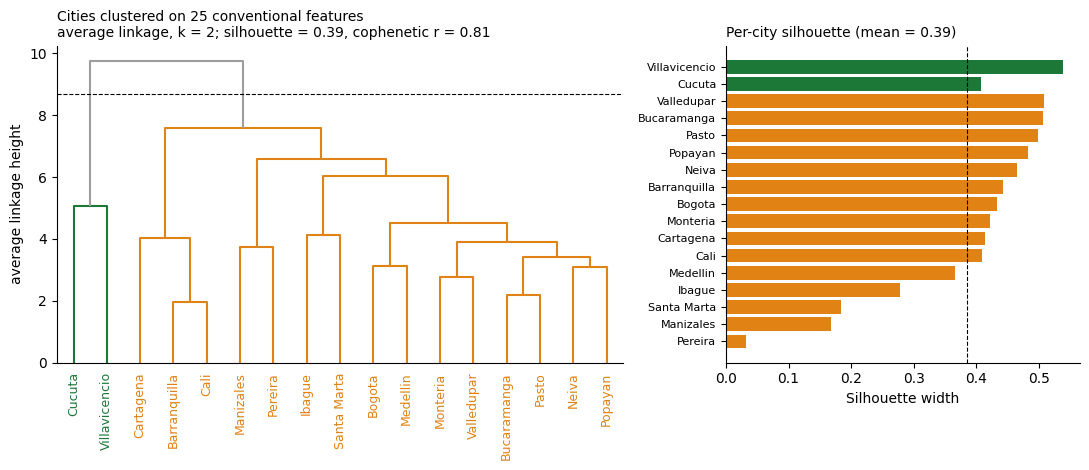


Feature profile (sorted by |z difference| between clusters):


,median_c1,median_c2,z_diff_c2_minus_c1
t_iqr,17.148,4.929,-2.716
t_p90,58.971,12.888,-2.664
gap_bajo_alto,10.734,-0.717,-2.548
share_gt30,0.208,0.012,-2.513
share_lt10,0.640,0.840,2.411
share_no_hc15,0.136,0.051,-2.349
share_beyond_800m_euclid,0.033,0.005,-2.295
share_ge2_hc15,0.736,0.897,2.149
t_p50,6.284,4.556,-1.884
catchment_pop_cv,2.598,1.302,-1.779



Memberships:


,cluster,silhouette
villavicencio,1,0.539
cucuta,1,0.407
valledupar,2,0.508
bucaramanga,2,0.507
pasto,2,0.499
popayan,2,0.483
neiva,2,0.465
barranquilla,2,0.442
bogota,2,0.434
monteria,2,0.423



ARI (feature clusters vs TDA superlevel-H0 split) = 0.060


TDA,TDA green,TDA orange
feature cluster,,
1,0,2
2,9,6


In [6]:
# ============================================================================
# CELL 1 — Hierarchical clustering of cities on the 15 conventional features (k = 2)
# ============================================================================
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram, cophenet
from scipy.spatial.distance import pdist
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

# ---- parameters -------------------------------------------------------------
FEATURE_CSV = OUT_CSV
K = 2
METHOD = "average"        # "ward" (Euclidean only), "average", "complete", "single"
METRIC = "euclidean"   # used by pdist when METHOD != "ward"
USE_PCA = None         # None = z-scored features; e.g. 0.90 = keep PCs explaining 90 % variance
COLORS = ["#1b7837", "#e08214"]          # cluster 1, cluster 2
ABOVE = "#9e9e9e"                        # links joining different clusters
OUT_DIR = FEATURE_CSV.parent / "feature_clustering"
OUT_DIR.mkdir(exist_ok=True)

# ---- data ---------------------------------------------------------------------
F = pd.read_csv(FEATURE_CSV, index_col="city")
assert F.notna().all().all(), F.columns[F.isna().any()].tolist()
cities = F.index.tolist()
Xz = (F - F.mean()) / F.std(ddof=0)                     # z-score: every feature weighs the same

if USE_PCA:
    from sklearn.decomposition import PCA
    pca = PCA(n_components=USE_PCA, svd_solver="full").fit(Xz)
    X = pca.transform(Xz)
    print(f"PCA: {pca.n_components_} components, {pca.explained_variance_ratio_.sum():.1%} variance")
else:
    X = Xz.to_numpy()

# ---- clustering ----------------------------------------------------------------
if METHOD == "ward":
    Z = linkage(X, method="ward")                       # Ward on Euclidean distances
    D = pdist(X, "euclidean")
else:
    D = pdist(X, METRIC)
    Z = linkage(D, method=METHOD)

labels = fcluster(Z, K, criterion="maxclust")
coph_r = cophenet(Z, D)[0]
sil = silhouette_score(X, labels, metric="euclidean" if METHOD == "ward" else METRIC)
sil_i = silhouette_samples(X, labels, metric="euclidean" if METHOD == "ward" else METRIC)
memb = pd.DataFrame({"cluster": labels, "silhouette": sil_i}, index=cities)

print(f"method = {METHOD}, k = {K}")
print(f"mean silhouette     = {sil:.3f}")
print(f"cophenetic corr.    = {coph_r:.3f}")
print("cluster sizes       =", memb.cluster.value_counts().sort_index().to_dict())

# ---- dendrogram colouring: a link gets a cluster colour only if all its leaves share that cluster
n = len(cities)
leaf_sets = {i: {labels[i]} for i in range(n)}
for j, (a, b, _, _) in enumerate(Z):
    leaf_sets[n + j] = leaf_sets[int(a)] | leaf_sets[int(b)]
link_color = lambda k: COLORS[next(iter(leaf_sets[k])) - 1] if len(leaf_sets[k]) == 1 else ABOVE
cut = (Z[-K, 2] + Z[-K + 1, 2]) / 2                     # height between the (K-1)th and Kth last merges

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.8), gridspec_kw={"width_ratios": [1.6, 1]})
R = dendrogram(Z, labels=[c.replace("_", " ").title() for c in cities], ax=ax1,
               link_color_func=link_color, leaf_rotation=90, leaf_font_size=9)
for tick, idx in zip(ax1.get_xticklabels(), R["leaves"]):
    tick.set_color(COLORS[labels[idx] - 1])
ax1.axhline(cut, ls="--", lw=0.8, color="k")
ax1.set_ylabel("Ward linkage height" if METHOD == "ward" else f"{METHOD} linkage height")
ax1.set_title(f"Cities clustered on {F.shape[1]} conventional features\n"
              f"{METHOD} linkage, k = {K}; silhouette = {sil:.2f}, cophenetic r = {coph_r:.2f}", loc="left", fontsize=10)
for s in ("top", "right"):
    ax1.spines[s].set_visible(False)

# silhouette plot (one bar per city, grouped by cluster)
order = memb.sort_values(["cluster", "silhouette"], ascending=[True, False])
y = np.arange(len(order))
ax2.barh(y, order.silhouette, color=[COLORS[c - 1] for c in order.cluster])
ax2.set_yticks(y, [c.replace("_", " ").title() for c in order.index], fontsize=8)
ax2.invert_yaxis()
ax2.axvline(sil, ls="--", lw=0.8, color="k")
ax2.axvline(0, lw=0.6, color="k")
ax2.set_xlabel("Silhouette width")
ax2.set_title(f"Per-city silhouette (mean = {sil:.2f})", loc="left", fontsize=10)
for s in ("top", "right"):
    ax2.spines[s].set_visible(False)
fig.tight_layout()
fig.savefig(OUT_DIR / f"dendrogram_features_{METHOD}_k{K}.png", dpi=300, bbox_inches="tight")
plt.show()

# ---- what separates the two clusters? -----------------------------------------
prof = pd.DataFrame({f"median_c{c}": F[labels == c].median() for c in range(1, K + 1)})
prof["z_diff_c2_minus_c1"] = Xz[labels == 2].mean() - Xz[labels == 1].mean()
prof = prof.reindex(prof.z_diff_c2_minus_c1.abs().sort_values(ascending=False).index)
print("\nFeature profile (sorted by |z difference| between clusters):")
display(prof.round(3))
print("\nMemberships:")
display(memb.sort_values(["cluster", "silhouette"], ascending=[True, False]).round(3))

# ---- optional: compare with the uniform-weight superlevel-H0 (TDA) split -------
TDA_GREEN = {"barranquilla", "bogota", "cali", "cartagena", "ibague", "manizales",
             "pasto", "popayan", "santa_marta"}
tda = np.array([1 if c in TDA_GREEN else 2 for c in cities])
print(f"\nARI (feature clusters vs TDA superlevel-H0 split) = {adjusted_rand_score(tda, labels):.3f}")
display(pd.crosstab(pd.Series(labels, index=cities, name="feature cluster"),
                    pd.Series(np.where(tda == 1, "TDA green", "TDA orange"), index=cities, name="TDA")))

memb.assign(tda_split=np.where(tda == 1, "green", "orange")).to_csv(OUT_DIR / f"memberships_{METHOD}_k{K}.csv")
prof.to_csv(OUT_DIR / f"cluster_profile_{METHOD}_k{K}.csv")

/opt/homebrew/anaconda3/envs/kernels/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/opt/homebrew/anaconda3/envs/kernels/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/opt/homebrew/anaconda3/envs/kernels/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/opt/homebrew/anaconda3/envs/kernels/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/opt/homebrew/anaconda3/envs/kernels/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/opt/homebrew/anaconda3/envs/kernels/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/opt/homebrew/anaconda3/envs/kernels

,method,k,n_found,cophenetic,smallest_cluster,n_singletons,silhouette,calinski_harabasz,davies_bouldin,boot_ARI_mean,boot_ARI_p10
0,ward,2,2,0.786,2,0,0.386,6.660,0.769,0.555,-0.094
1,ward,3,3,0.786,2,0,0.325,8.681,0.804,0.650,0.234
2,ward,4,4,0.786,2,0,0.297,8.993,0.834,0.629,0.375
3,ward,5,5,0.786,2,0,0.335,10.068,0.804,0.818,0.569
4,ward,6,6,0.786,2,0,0.283,9.848,0.844,0.827,0.604
5,ward,7,7,0.786,2,0,0.271,9.287,0.848,0.800,0.580
6,ward,8,8,0.786,1,2,0.230,9.256,0.734,0.792,0.589
7,average,2,2,0.812,2,0,0.386,6.660,0.769,0.880,0.441
8,average,3,3,0.812,2,0,0.325,8.681,0.804,0.731,0.234
9,average,4,4,0.812,2,0,0.297,8.993,0.834,0.792,0.462


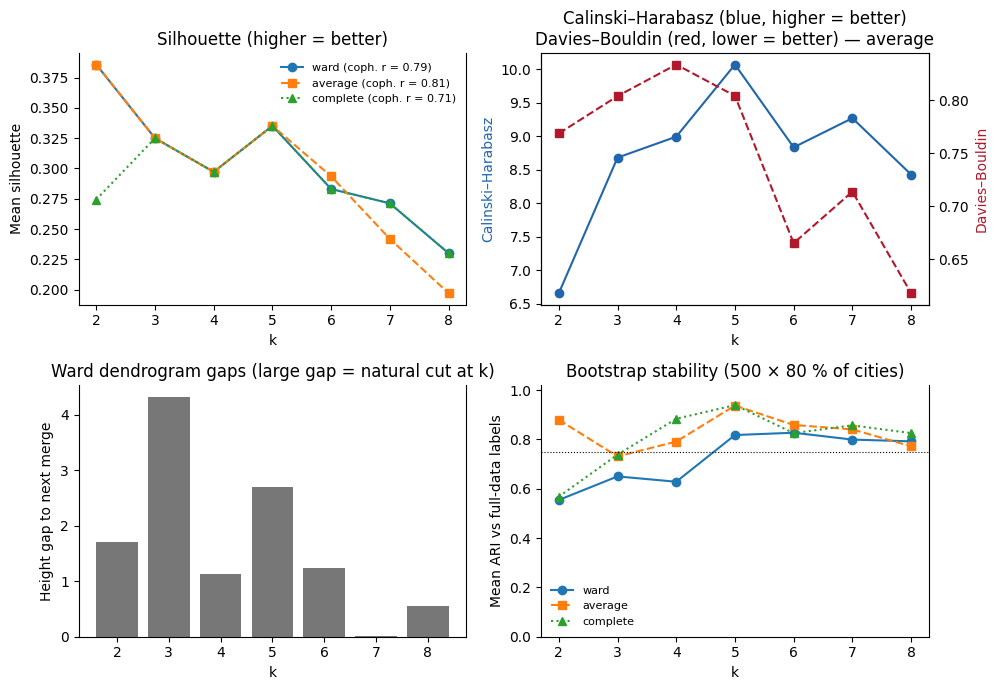

average: best silhouette without singleton clusters at k = 2 (silhouette = 0.386, bootstrap ARI = 0.88)


,k2,k3,k4,k5,k6,k7,k8
cucuta,1,1,1,1,1,1,1
villavicencio,1,1,1,1,2,2,2
barranquilla,2,2,2,2,3,3,3
cali,2,2,2,2,3,3,3
cartagena,2,2,2,2,3,3,3
manizales,2,3,3,3,4,4,4
pereira,2,3,3,3,4,4,4
ibague,2,3,4,4,5,5,5
santa_marta,2,3,4,4,5,5,6
bogota,2,3,4,5,6,6,7


In [7]:
# ============================================================================
# CELL 2 — How many clusters? (uses X, Xz, F, cities, METHOD, METRIC, OUT_DIR from Cell 1)
# ============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, fcluster, cophenet
from scipy.spatial.distance import pdist
from sklearn.metrics import (silhouette_score, calinski_harabasz_score,
                             davies_bouldin_score, adjusted_rand_score)

K_RANGE = range(2, 9)                     # 17 cities -> k beyond ~8 leaves mostly singletons
METHODS = ["ward", "average", "complete"]
N_BOOT = 500                              # bootstrap resamples for stability
FRAC = 0.8                                # fraction of cities kept in each resample
rng = np.random.default_rng(0)


def cluster(Xm, method, k):
    Zm = linkage(Xm, "ward") if method == "ward" else linkage(pdist(Xm, METRIC), method)
    return fcluster(Zm, k, "maxclust"), Zm


rows, links = [], {}
for method in METHODS:
    _, Zm = cluster(X, method, 2)
    links[method] = Zm
    coph = cophenet(Zm, pdist(X, "euclidean" if method == "ward" else METRIC))[0]
    for k in K_RANGE:
        lab, _ = cluster(X, method, k)
        n_found = len(np.unique(lab))
        sizes = np.bincount(lab)[1:]
        r = dict(method=method, k=k, n_found=n_found, cophenetic=coph,
                 smallest_cluster=int(sizes.min()), n_singletons=int((sizes == 1).sum()))
        if n_found > 1:
            r["silhouette"] = silhouette_score(X, lab, metric="euclidean" if method == "ward" else METRIC)
            r["calinski_harabasz"] = calinski_harabasz_score(X, lab)
            r["davies_bouldin"] = davies_bouldin_score(X, lab)
        # bootstrap stability: re-cluster 80 % subsamples, ARI with the full-data labels on the kept cities
        aris = []
        for _ in range(N_BOOT):
            keep = np.sort(rng.choice(len(X), int(round(FRAC * len(X))), replace=False))
            lab_b, _ = cluster(X[keep], method, k)
            aris.append(adjusted_rand_score(lab[keep], lab_b))
        r["boot_ARI_mean"] = np.mean(aris)
        r["boot_ARI_p10"] = np.quantile(aris, 0.10)
        rows.append(r)

K_TAB = pd.DataFrame(rows)
display(K_TAB.round(3))

# elbow on Ward merge heights: a large jump between consecutive merges suggests a natural cut
Zw = links["ward"]
h = Zw[::-1, 2]                                    # h[0] = last merge (k=1 -> 2), h[1] = (2 -> 3), ...
elbow = pd.DataFrame({"k": np.arange(2, len(h) + 1)[:len(K_RANGE)],
                      "merge_height": h[:len(K_RANGE)],
                      "jump_to_next": (h[:len(K_RANGE)] - h[1:len(K_RANGE) + 1])})

# ---- figure ---------------------------------------------------------------------
fig, axs = plt.subplots(2, 2, figsize=(10, 7))
mk = {"ward": "o-", "average": "s--", "complete": "^:"}
ax = axs[0, 0]
for m in METHODS:
    t = K_TAB[K_TAB.method == m]
    ax.plot(t.k, t.silhouette, mk[m], label=f"{m} (coph. r = {t.cophenetic.iloc[0]:.2f})")
ax.set(xlabel="k", ylabel="Mean silhouette", title="Silhouette (higher = better)")
ax.legend(frameon=False, fontsize=8)

ax = axs[0, 1]
t = K_TAB[K_TAB.method == METHOD]
ax.plot(t.k, t.calinski_harabasz, "o-", color="#2166ac")
ax.set(xlabel="k", title=f"Calinski–Harabasz (blue, higher = better)\nDavies–Bouldin (red, lower = better) — {METHOD}")
ax.set_ylabel("Calinski–Harabasz", color="#2166ac")
ax_b = ax.twinx()
ax_b.plot(t.k, t.davies_bouldin, "s--", color="#b2182b")
ax_b.set_ylabel("Davies–Bouldin", color="#b2182b")

ax = axs[1, 0]
ax.bar(elbow.k, elbow.jump_to_next, color="#777777")
ax.set(xlabel="k", ylabel="Height gap to next merge",
       title="Ward dendrogram gaps (large gap = natural cut at k)")

ax = axs[1, 1]
for m in METHODS:
    t = K_TAB[K_TAB.method == m]
    ax.plot(t.k, t.boot_ARI_mean, mk[m], label=m)
ax.axhline(0.75, ls=":", lw=0.8, color="k")
ax.set(xlabel="k", ylabel="Mean ARI vs full-data labels", ylim=(0, 1.02),
       title=f"Bootstrap stability ({N_BOOT} × {int(FRAC*100)} % of cities)")
ax.legend(frameon=False, fontsize=8)
for a in axs.flat:
    a.set_xticks(list(K_RANGE))
    for s in ("top",):
        a.spines[s].set_visible(False)
fig.tight_layout()
fig.savefig(OUT_DIR / "n_clusters_analysis.png", dpi=300, bbox_inches="tight")
plt.show()

# ---- summary and memberships for each k (main method) ----------------------------
best = K_TAB[(K_TAB.method == METHOD) & (K_TAB.n_singletons == 0)]
if len(best):
    b = best.loc[best.silhouette.idxmax()]
    print(f"{METHOD}: best silhouette without singleton clusters at k = {int(b.k)} "
          f"(silhouette = {b.silhouette:.3f}, bootstrap ARI = {b.boot_ARI_mean:.2f})")
MEMB_K = pd.DataFrame({f"k{k}": cluster(X, METHOD, k)[0] for k in K_RANGE}, index=cities)
display(MEMB_K.sort_values(list(MEMB_K.columns)))

K_TAB.to_csv(OUT_DIR / "n_clusters_metrics.csv", index=False)
MEMB_K.to_csv(OUT_DIR / f"memberships_by_k_{METHOD}.csv")